# Resultados del pronóstico IA

Facatativá, extensión de la Universidad de Cundinamarca. Referencia: estación 3.
Este cuaderno carga los resultados y modelos ya entrenados; no vuelve a entrenar al abrirlo.
Para reproducir el ajuste completo: `python entrenar_pronostico.py`.
Para nuevas entradas horarias: `python predecir.py --dataset datos_horarios.csv`.
El método, las unidades y el alcance de la evaluación están en **RESULTADOS.md**.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
root = Path.cwd()
if not (root / 'resultados').exists():
    raise RuntimeError('Ejecuta este cuaderno desde la carpeta pronostico ia')
metrics = pd.read_csv(root / 'resultados/metricas_regresion.csv')
selected = metrics[(metrics.particion == 'test') & (metrics.modelo == 'sistema_seleccionado')]
display(selected[['variable', 'horizonte', 'mae', 'rmse', 'r2', 'n_pares', 'horas_distintas']])

,variable,horizonte,mae,rmse,r2,n_pares,horas_distintas
109,tem,1-48h,1.377922,2.256873,0.704062,349,88
120,tem,1-24h,1.366379,2.196045,0.711248,227,86
131,tem,25-48h,1.399400,2.365895,0.691413,122,41
142,hum,1-48h,3.271684,7.190979,0.065393,349,88
153,hum,1-24h,3.101484,6.584400,0.177503,227,86
164,hum,25-48h,3.588366,8.201070,-0.117301,122,41
175,rad,1-48h,2189.983555,4180.552094,0.910678,345,87
186,rad,1-24h,2258.531332,4207.367015,0.908866,223,85
197,rad,25-48h,2064.687210,4131.088114,0.913902,122,41


## Validación y arquitectura

,modelo,ventanas_train,ventanas_val,parametros,epocas,epoca_restaurada
0,lstm_local,389,6,1546,19,7
1,lstm_historicos,389,6,1546,19,7
2,lstm_auxiliar,664,10,1382,22,10


,variable,modelo,mae,rmse,sesgo,r2,n_pares
0,tem,lstm_local,1.450834,1.998077,0.870168,0.574057,254
1,tem,lstm_historicos,1.406974,1.978752,0.778375,0.582256,254
2,tem,lstm_auxiliar,1.528492,2.110493,0.933020,0.524780,254
3,tem,persistencia_24h,1.442906,1.979846,1.026710,0.581794,254
4,tem,mediana_horaria,1.651892,2.053035,0.805073,0.550303,254
5,tem,ridge_10,1.763249,2.122172,0.408191,0.519506,254
6,tem,ridge_100,1.749193,2.108055,0.419972,0.525877,254
7,tem,lstm_local_mezcla50,1.411236,1.967735,0.948439,0.586895,254
8,tem,lstm_historicos_mezcla50,1.348089,1.932478,0.902542,0.601566,254
9,tem,lstm_auxiliar_mezcla50,1.390668,1.983561,0.979865,0.580223,254


,variable,horizonte,cobertura_prueba,n_pares,margen
0,tem,1-24h,0.881057,227,3.419112
1,tem,25-48h,0.909836,122,3.947840
2,hum,1-24h,0.819383,227,6.444998
3,hum,25-48h,0.868852,122,11.808558
4,rad,1-24h,0.950673,223,11599.761988
5,rad,25-48h,0.942623,122,10071.534115


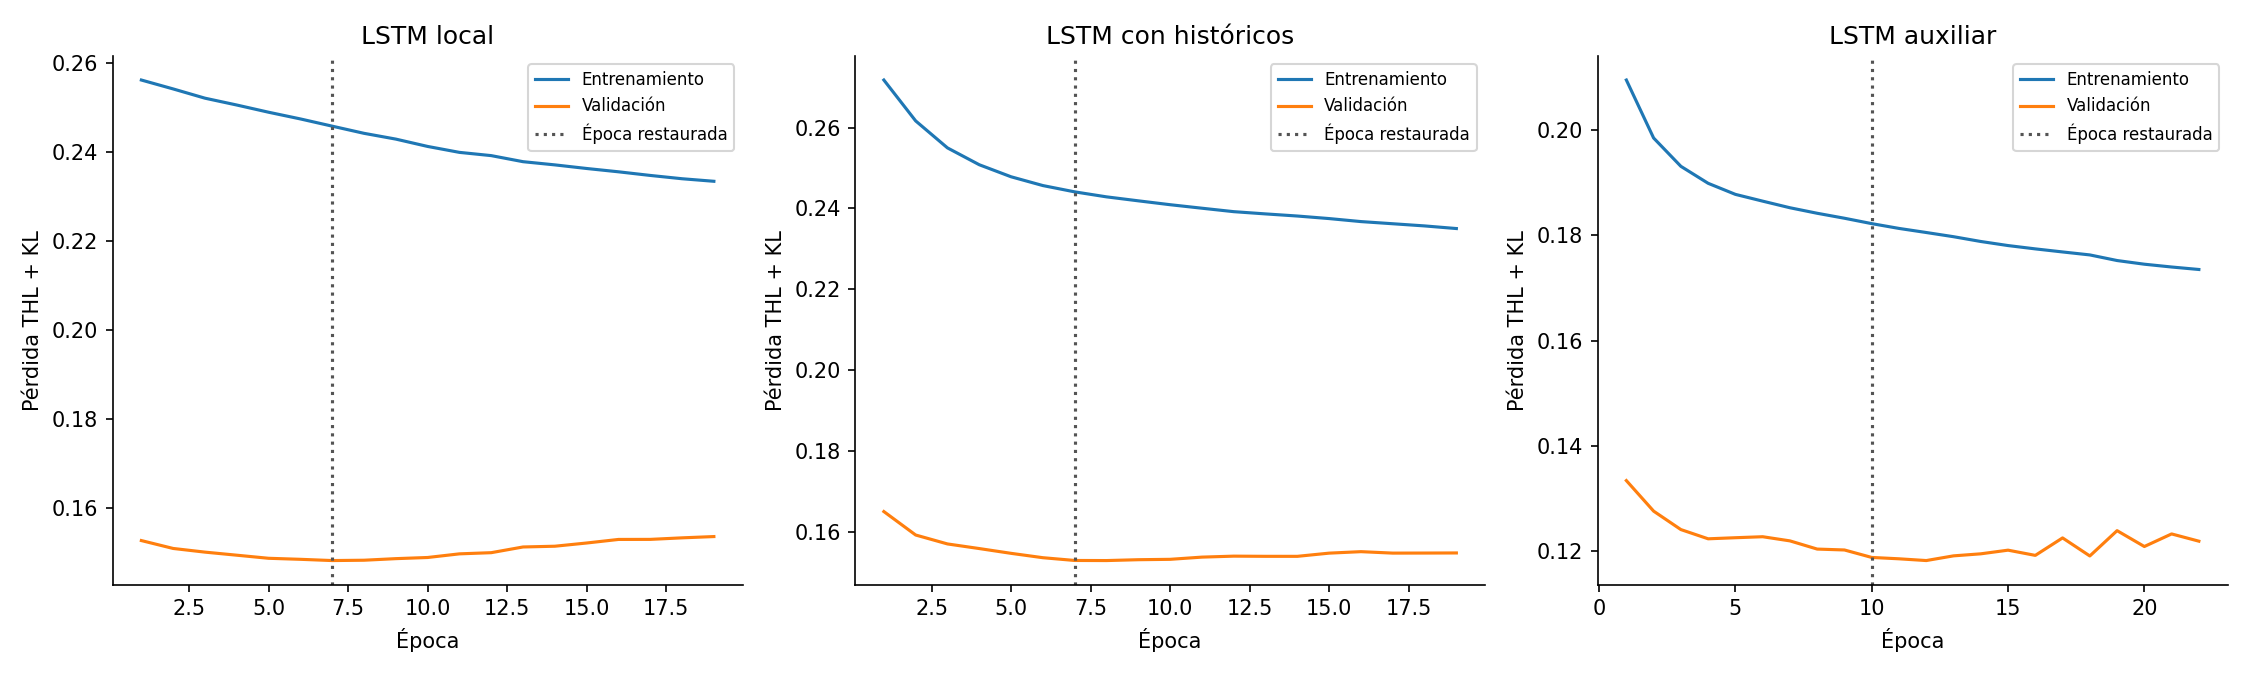

In [2]:
summary = json.loads((root / 'resultados/resumen_entrenamiento.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'modelo': name, 'ventanas_train': spec['datos']['ventanas'],
                      'ventanas_val': spec['validacion']['ventanas'], 'parametros': spec['parametros'],
                      'epocas': spec['epocas'], 'epoca_restaurada': spec['epoca_restaurada']}
                     for name, spec in summary['corridas'].items()]))
display(pd.read_csv(root / 'resultados/seleccion_validacion.csv'))
display(pd.read_csv(root / 'resultados/cobertura_rangos.csv'))
display(Image(filename=str(root / 'resultados/curvas_entrenamiento.png')))

## Pronóstico del siguiente día

,fecha,franja,condicion_orientativa,temperatura_media_c,temperatura_min_curva_c,temperatura_max_curva_c,humedad_media_pct,luz_media_lux,lluvia_era5_estimada_mm,confianza_clase_calibrada,horas
0,2026-10-16,Madrugada,Cielo no determinado,11.902458,10.687873,12.668598,99.900000,21.380556,0.017290,NaN,6
1,2026-10-16,Mañana,Posible lluvia,19.277554,13.654391,24.777327,84.566437,19621.389648,1.083717,NaN,6
2,2026-10-16,Tarde,Posible lluvia,21.573799,14.987433,26.961752,81.992207,20408.225412,2.002939,NaN,6
3,2026-10-16,Noche,Posible lluvia,12.242969,11.289866,13.295083,99.900000,0.233333,0.633606,NaN,6


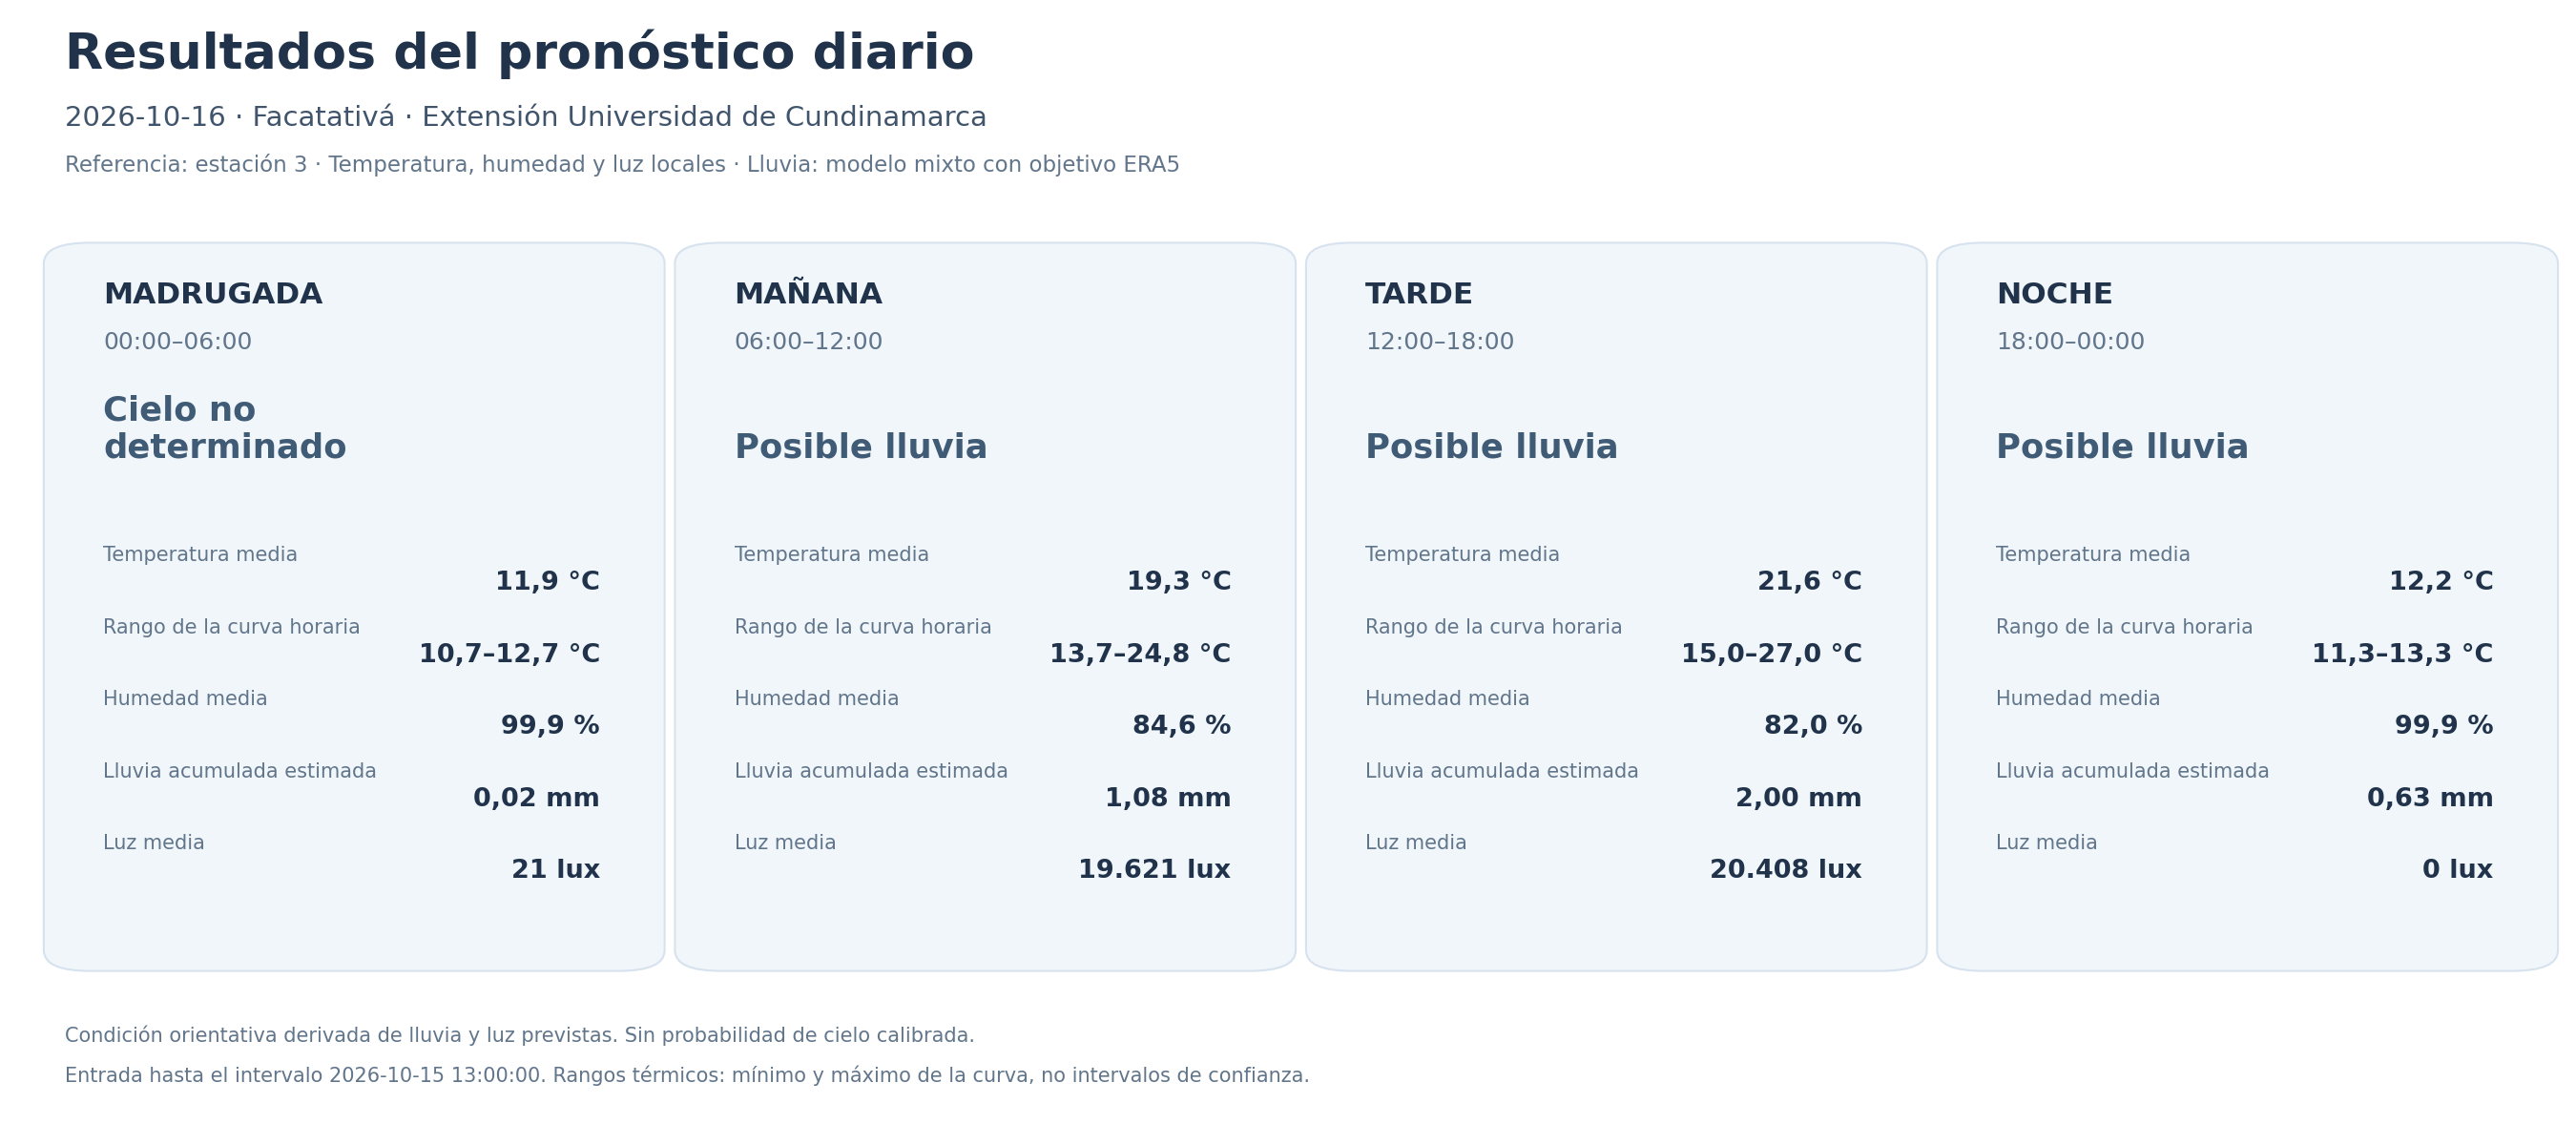

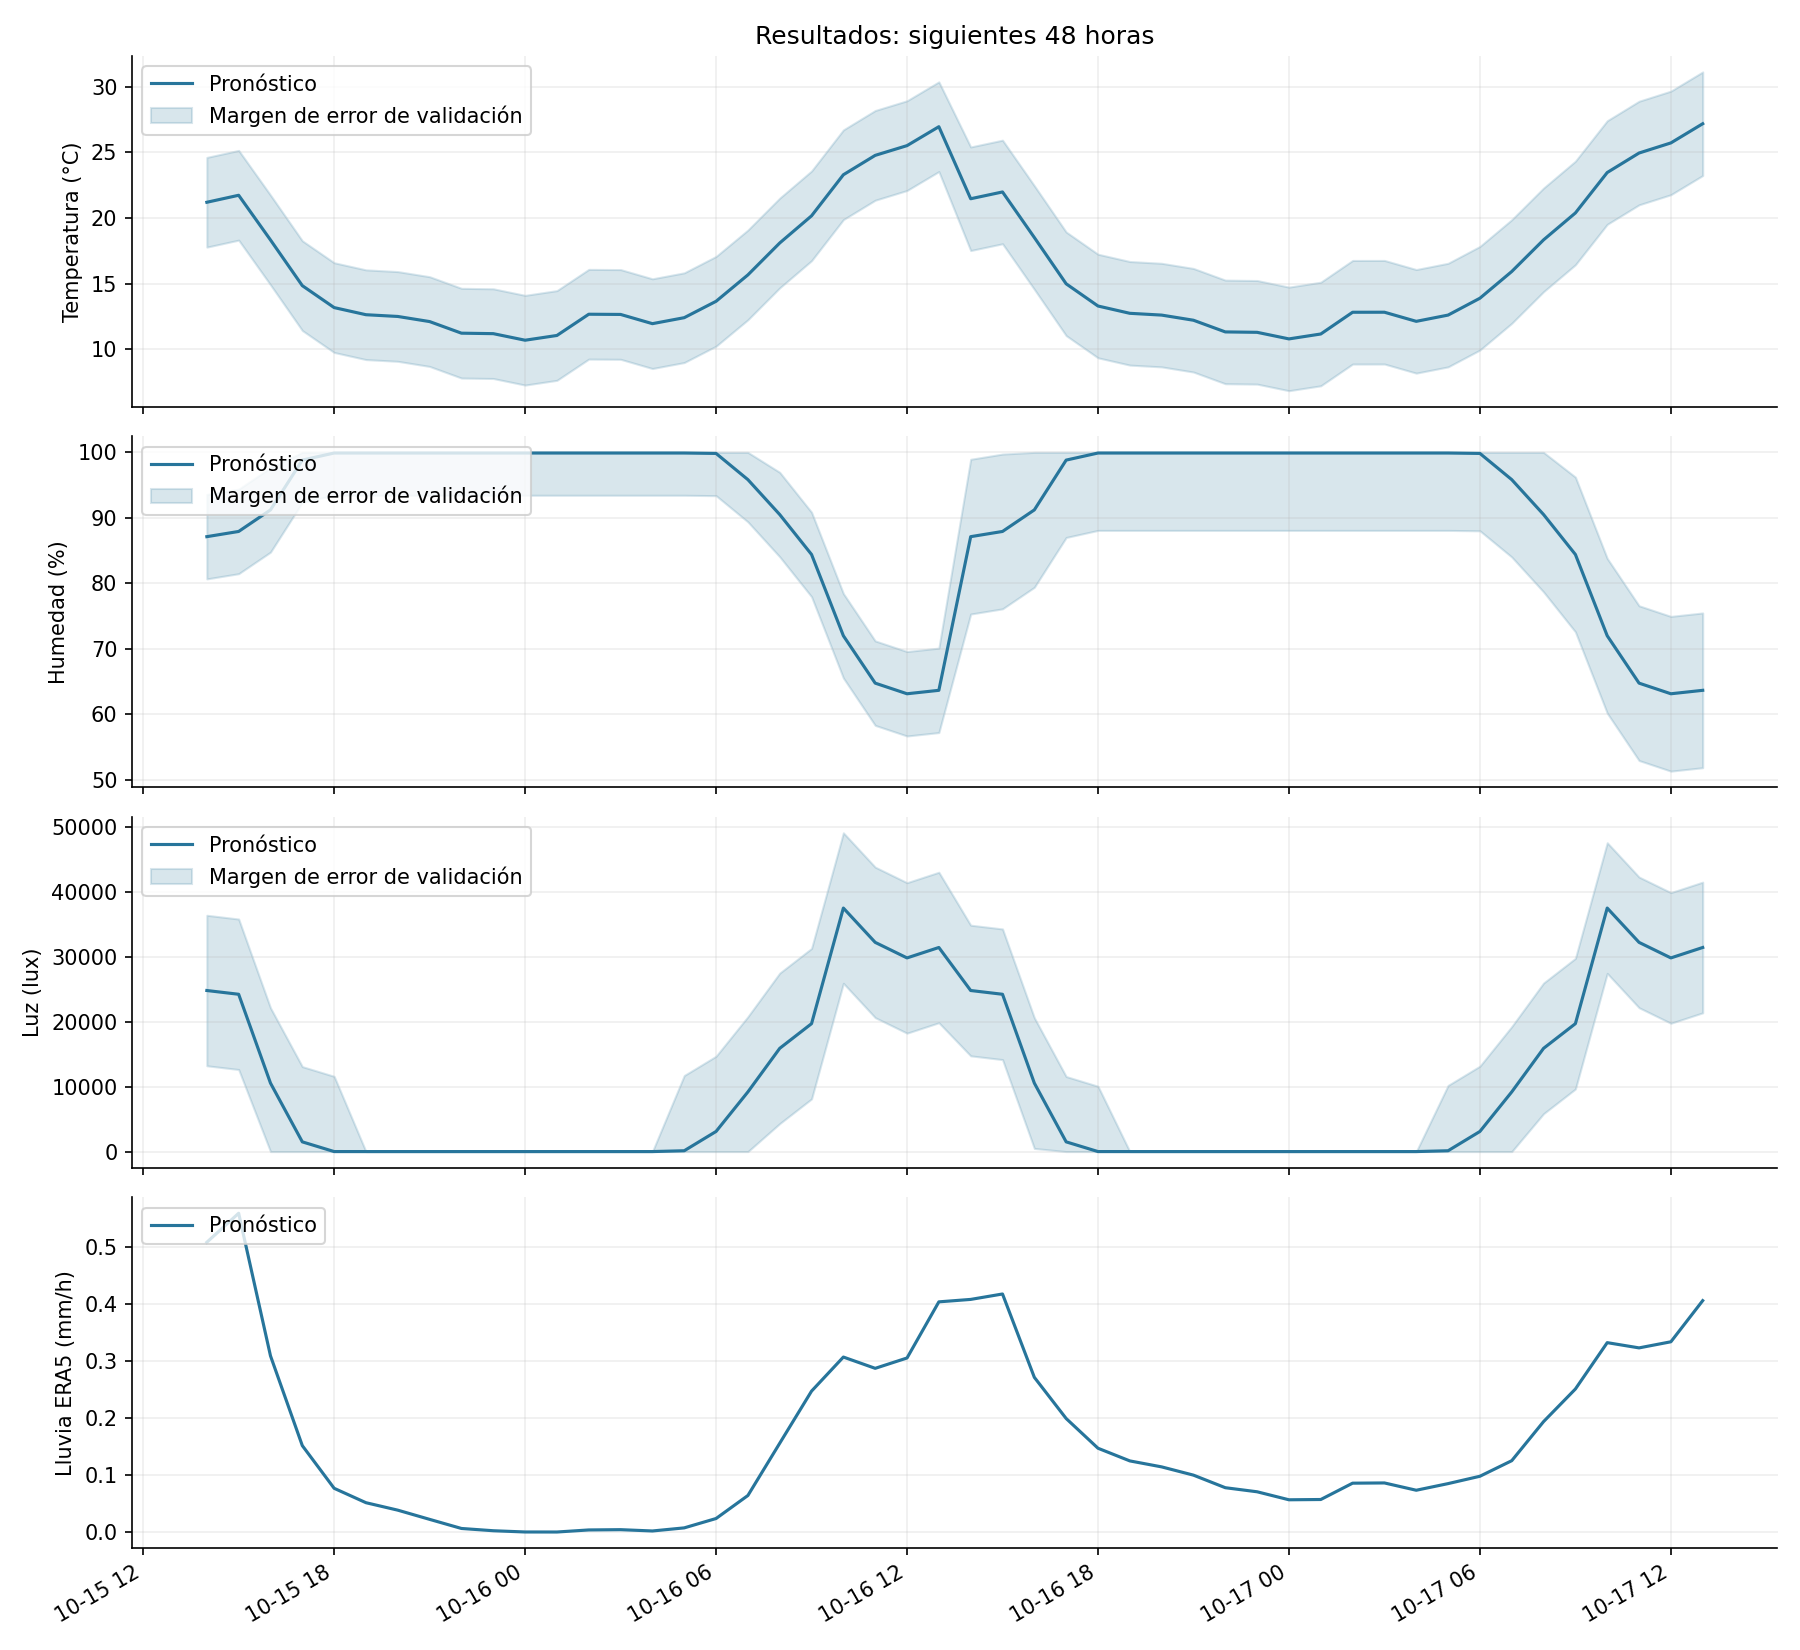

In [3]:
display(pd.read_csv(root / 'resultados/pronostico_diario.csv'))
display(Image(filename=str(root / 'resultados/pronostico_diario.png')))
display(Image(filename=str(root / 'resultados/pronostico_variables.png')))

## Errores y clasificación binaria de lluvia

THL se evalúa como regresión. La matriz de lluvia conserva la prueba de v16 contra ERA5 ≥0,1 mm/h. No es una matriz de soleado/nublado/lluvioso.

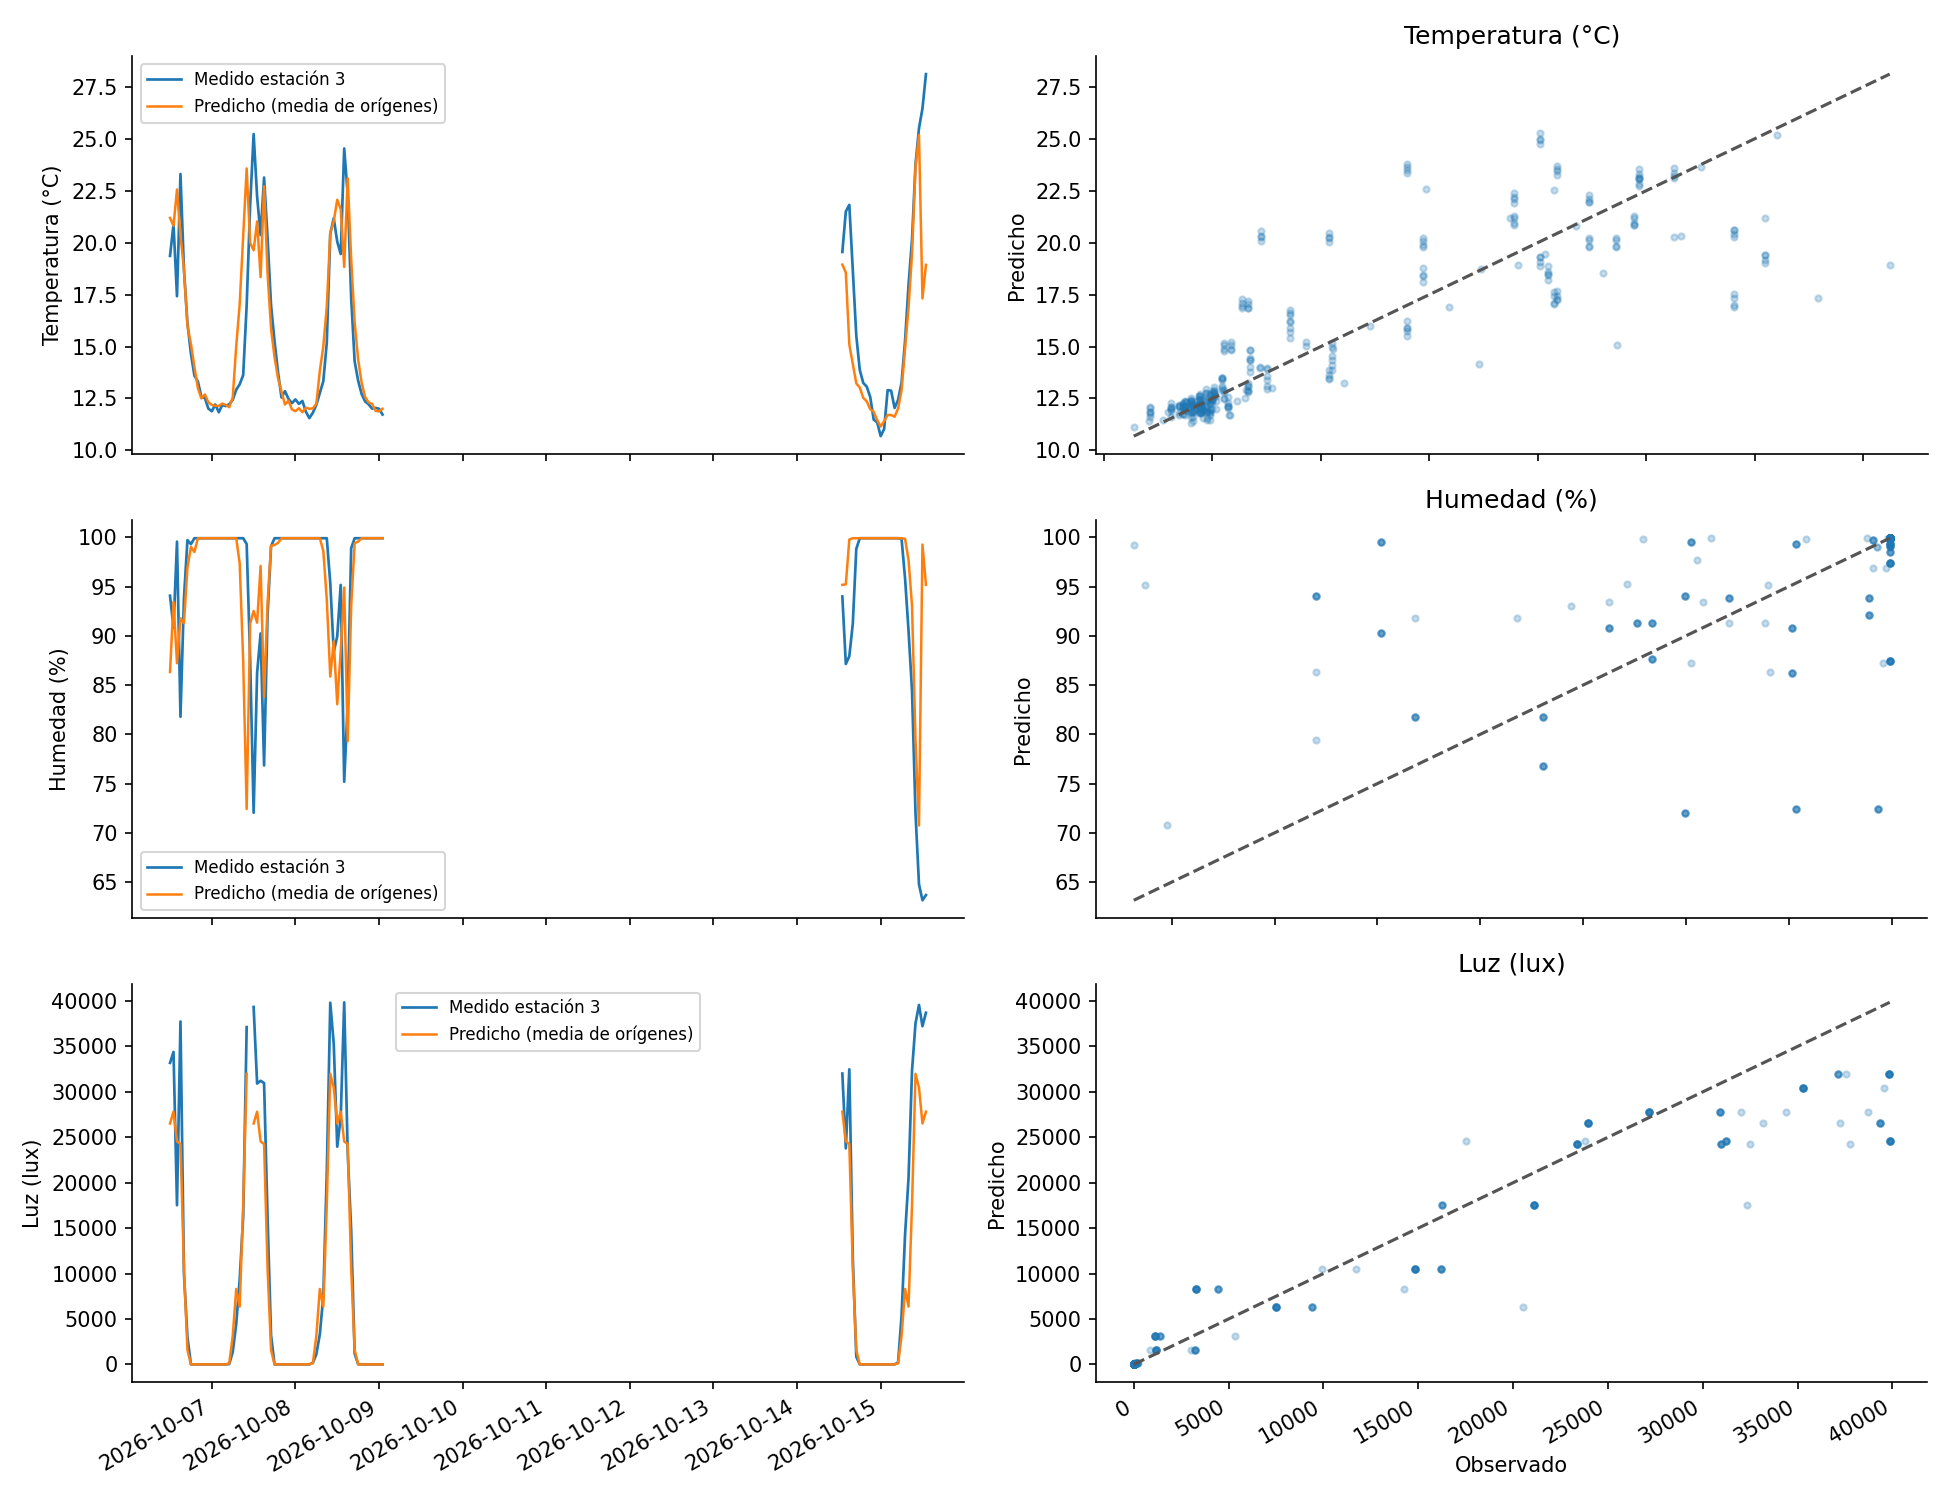

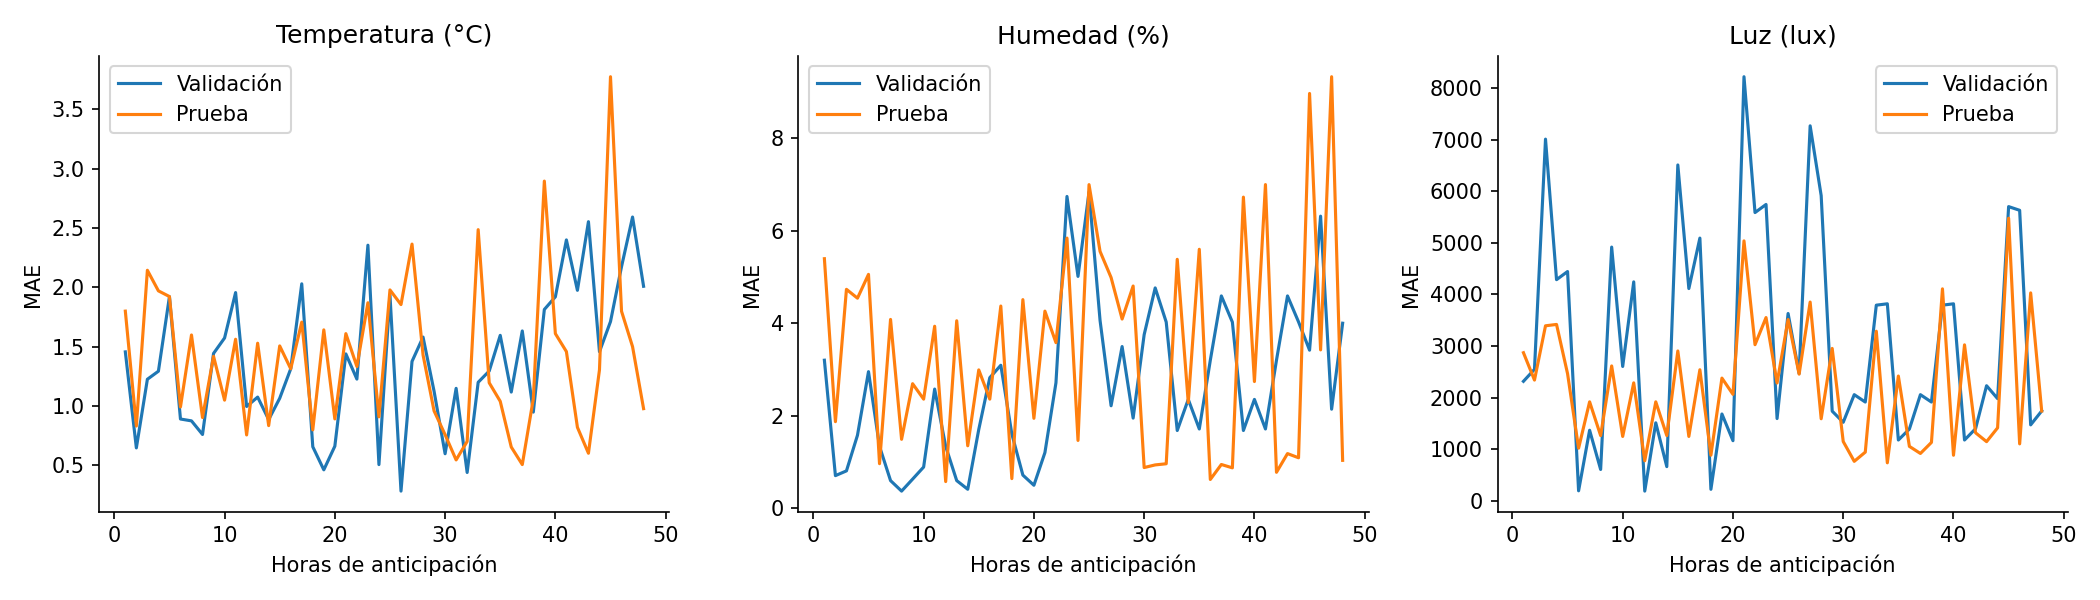

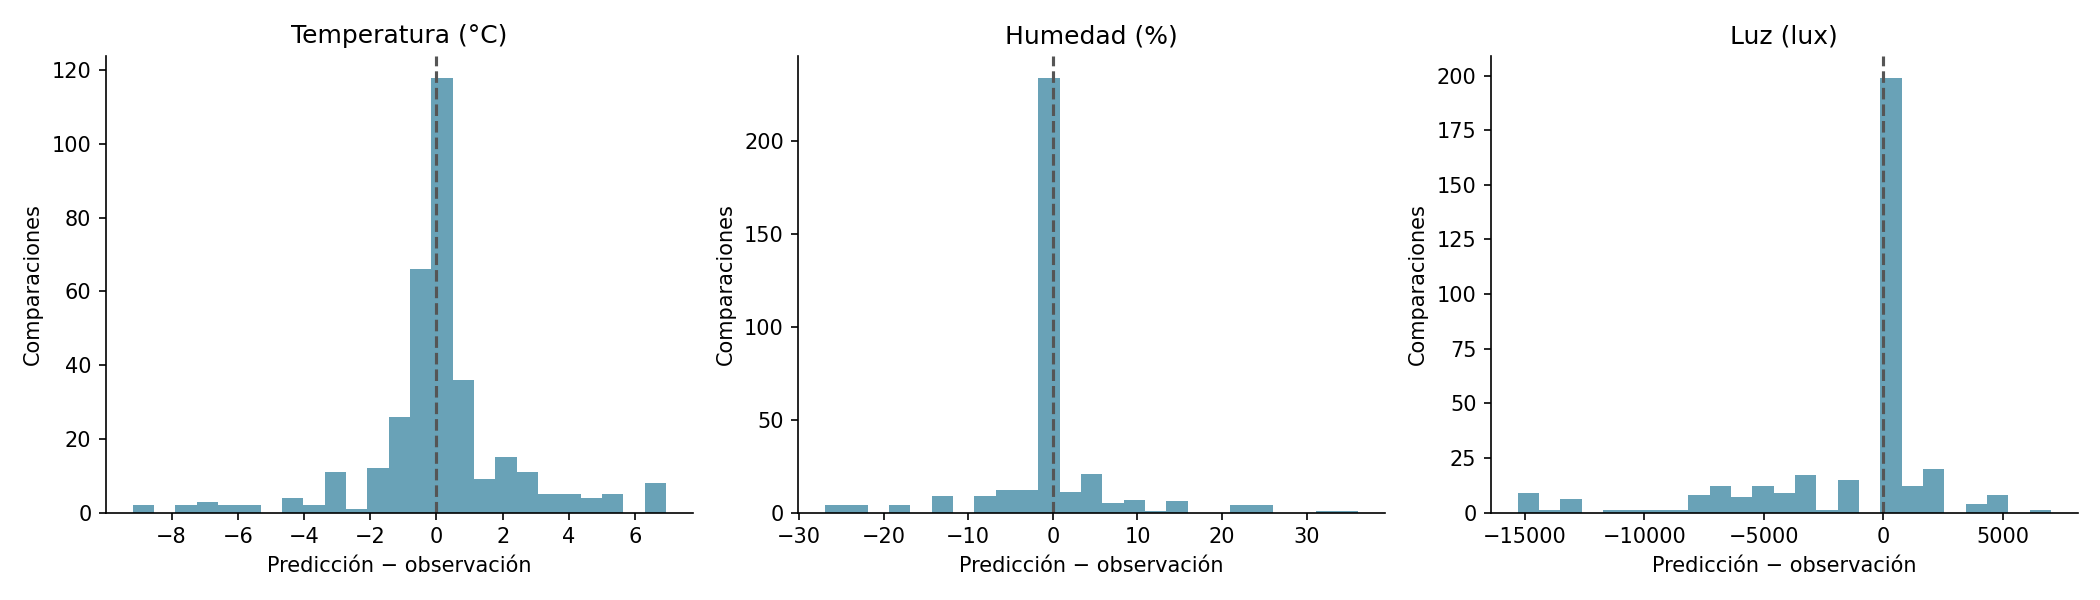

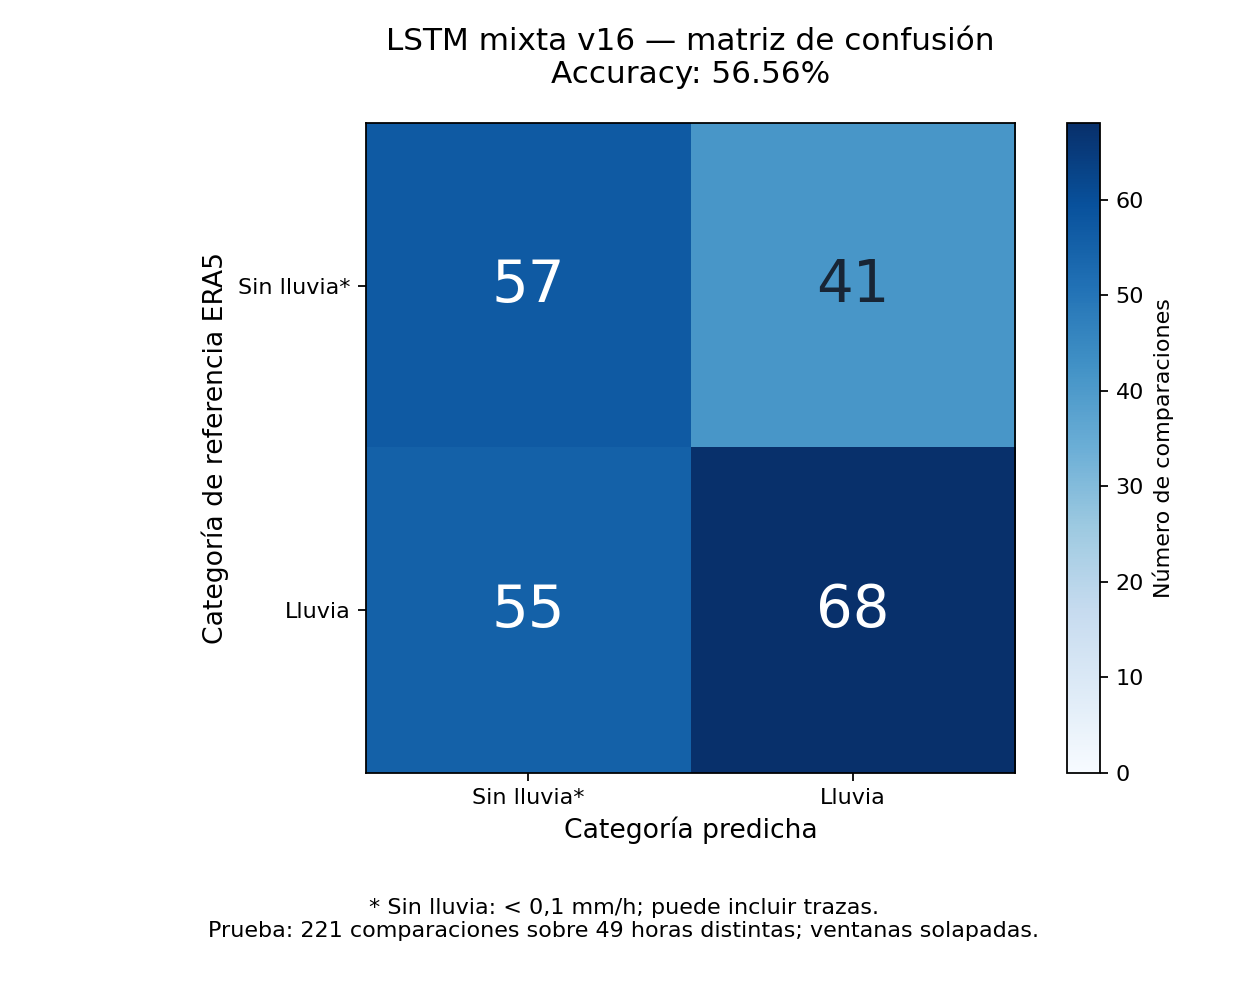

Accuracy de lluvia: 0.5656108597285068


,categoria,precision,recall,f1_score,soporte
0,Sin lluvia*,0.508929,0.581633,0.542857,98
1,Lluvia,0.623853,0.552846,0.586207,123


In [4]:
display(Image(filename=str(root / 'resultados/errores_prueba.png')))
display(Image(filename=str(root / 'resultados/errores_por_horizonte.png')))
display(Image(filename=str(root / 'resultados/distribucion_errores.png')))
display(Image(filename=str(root / 'lluvia/matriz_confusion_prueba.png')))
rain = json.loads((root / 'lluvia/metricas_clasificacion_prueba.json').read_text(encoding='utf-8'))
print('Accuracy de lluvia:', rain['accuracy'])
display(pd.DataFrame(rain['por_categoria']))